In [69]:
import pandas as pd
import matplotlib.pyplot as plt
import re

In [27]:
df = pd.read_csv("../data/raw/Resume.csv")

In [28]:
# Checking The File: Gathering Info

In [29]:
df.head()

,ID,Resume_str,Resume_html,Category
0,16852973,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,"<div class=""fontsize fontface vmargins hmargin...",HR
1,22323967,"HR SPECIALIST, US HR OPERATIONS ...","<div class=""fontsize fontface vmargins hmargin...",HR
2,33176873,HR DIRECTOR Summary Over 2...,"<div class=""fontsize fontface vmargins hmargin...",HR
3,27018550,HR SPECIALIST Summary Dedica...,"<div class=""fontsize fontface vmargins hmargin...",HR
4,17812897,HR MANAGER Skill Highlights ...,"<div class=""fontsize fontface vmargins hmargin...",HR


In [30]:
df.shape

(2484, 4)

In [31]:
df.columns

Index(['ID', 'Resume_str', 'Resume_html', 'Category'], dtype='str')

In [32]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2484 entries, 0 to 2483
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   ID           2484 non-null   int64
 1   Resume_str   2484 non-null   str  
 2   Resume_html  2484 non-null   str  
 3   Category     2484 non-null   str  
dtypes: int64(1), str(3)
memory usage: 77.8 KB


In [33]:
df.isnull().sum()

ID             0
Resume_str     0
Resume_html    0
Category       0
dtype: int64

In [34]:
df

,ID,Resume_str,Resume_html,Category
0,16852973,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,"<div class=""fontsize fontface vmargins hmargin...",HR
1,22323967,"HR SPECIALIST, US HR OPERATIONS ...","<div class=""fontsize fontface vmargins hmargin...",HR
2,33176873,HR DIRECTOR Summary Over 2...,"<div class=""fontsize fontface vmargins hmargin...",HR
3,27018550,HR SPECIALIST Summary Dedica...,"<div class=""fontsize fontface vmargins hmargin...",HR
4,17812897,HR MANAGER Skill Highlights ...,"<div class=""fontsize fontface vmargins hmargin...",HR
...,...,...,...,...
2479,99416532,RANK: SGT/E-5 NON- COMMISSIONED OFFIC...,"<div class=""fontsize fontface vmargins hmargin...",AVIATION
2480,24589765,"GOVERNMENT RELATIONS, COMMUNICATIONS ...","<div class=""fontsize fontface vmargins hmargin...",AVIATION
2481,31605080,GEEK SQUAD AGENT Professional...,"<div class=""fontsize fontface vmargins hmargin...",AVIATION
2482,21190805,PROGRAM DIRECTOR / OFFICE MANAGER ...,"<div class=""fontsize fontface vmargins hmargin...",AVIATION


In [52]:
df.duplicated().sum()


np.int64(0)

In [53]:
df[["Resume_str", "Category"]].duplicated().sum()

np.int64(2)

In [36]:
df['Category'].value_counts()

Category
INFORMATION-TECHNOLOGY    120
BUSINESS-DEVELOPMENT      120
ADVOCATE                  118
CHEF                      118
FINANCE                   118
ENGINEERING               118
ACCOUNTANT                118
FITNESS                   117
AVIATION                  117
SALES                     116
HEALTHCARE                115
CONSULTANT                115
BANKING                   115
CONSTRUCTION              112
PUBLIC-RELATIONS          111
HR                        110
DESIGNER                  107
ARTS                      103
TEACHER                   102
APPAREL                    97
DIGITAL-MEDIA              96
AGRICULTURE                63
AUTOMOBILE                 36
BPO                        22
Name: count, dtype: int64

In [37]:
df['Category'].nunique()

24

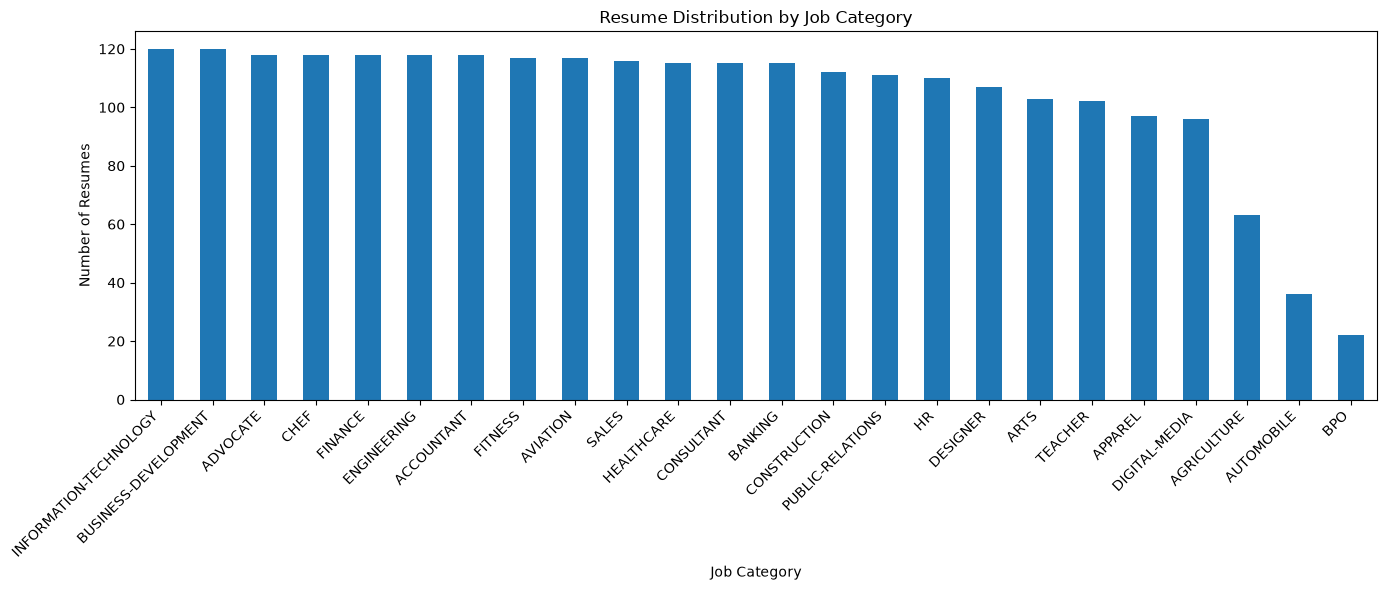

In [39]:
# visualization 
df["Category"].value_counts().plot(kind="bar", figsize=(14, 6))

plt.title("Resume Distribution by Job Category")
plt.xlabel("Job Category")
plt.ylabel("Number of Resumes")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [40]:
print(df["Resume_str"].iloc[0])

         HR ADMINISTRATOR/MARKETING ASSOCIATE

HR ADMINISTRATOR       Summary     Dedicated Customer Service Manager with 15+ years of experience in Hospitality and Customer Service Management.   Respected builder and leader of customer-focused teams; strives to instill a shared, enthusiastic commitment to customer service.         Highlights         Focused on customer satisfaction  Team management  Marketing savvy  Conflict resolution techniques     Training and development  Skilled multi-tasker  Client relations specialist           Accomplishments      Missouri DOT Supervisor Training Certification  Certified by IHG in Customer Loyalty and Marketing by Segment   Hilton Worldwide General Manager Training Certification  Accomplished Trainer for cross server hospitality systems such as    Hilton OnQ  ,   Micros    Opera PMS   , Fidelio    OPERA    Reservation System (ORS) ,   Holidex    Completed courses and seminars in customer service, sales strategies, inventory control, loss preve

In [41]:
print(df["Resume_str"].iloc[1])

         HR SPECIALIST, US HR OPERATIONS       Summary     Versatile  media professional with background in Communications, Marketing, Human Resources and Technology.         Experience     09/2015   to   Current     HR Specialist, US HR Operations    Company Name   －   City  ,   State       Managed communication regarding launch of Operations group, policy changes and system outages      Designed standard work and job aids to create comprehensive training program for new employees and contractors         Audited job postings for old, pending, on-hold and draft positions.           Audited union hourly, non-union hourly and salary background checks and drug screens             Conducted monthly new hire benefits briefing to new employees across all business units               Served as a link between HR Managers and vendors by handling questions and resolving system-related issues         Provide real-time process improvement feedback on key metrics and initiatives  Successfully re-br

In [46]:
# Check for shortest resume
df[df["text_length"] < 100][["Category", "Resume_str"]]

,Category,Resume_str
656,BUSINESS-DEVELOPMENT,


In [47]:
# Check for Largest resume
df.nlargest(5, "text_length")[["Category", "text_length"]]

,Category,text_length
1366,CHEF,38842
2111,PUBLIC-RELATIONS,35933
2007,CONSTRUCTION,30055
94,HR,24834
1817,ACCOUNTANT,24695


In [55]:
df["html_length"] = df["Resume_html"].str.len()

df[["text_length", "html_length"]].describe()

,text_length,html_length
count,2484.000000,2484.000000
mean,6295.308776,15711.218196
std,2769.251458,4997.827150
min,21.000000,1127.000000
25%,5160.000000,12800.750000
50%,5886.500000,15025.500000
75%,7227.250000,17823.500000
max,38842.000000,61959.000000


In [58]:
print(df.loc[656, "Resume_str"])

In [59]:
print("Length:", len(df.loc[656, "Resume_str"]))
print("Category:", df.loc[656, "Category"])

Length: 21
Category: BUSINESS-DEVELOPMENT


In [60]:
print(df.loc[1366, "Resume_str"][:3000])

         CHEF       Credentials     National Registry of Food Safety Professionals Certified Food Safety Manager  National Registry of Food Safety Professionals Test Administrator/Proctor       Education and Training      High School Diploma     Jun 1991     Newington High School   －   City  ,   State            Summary    Passionate Chef with broad background in various culinary styles and positions. A natural leader with excellent interpersonal communication skills and the ability to get things done overcoming any obstacles.       Accomplishments     Voted Best Restaurant 2013  Multiple "Best Of" accolades       Experience      Chef     Oct 2016   to   Current      Company Name   －   City  ,   State       All aspects of an independently operated Hospital kitchen including staffing, payroll, menus, inventory/ordering, P&L, employee training and discipline, cleaning and equipment maintenance.      Monitor p&l and food and labor costs to maximize budget and minimize waste.      Intervie

In [61]:
print("Duplicate Resume_str:", df["Resume_str"].duplicated().sum())

print(
    "Duplicate Resume_str + Category:",
    df[["Resume_str", "Category"]].duplicated().sum()
)

Duplicate Resume_str: 2
Duplicate Resume_str + Category: 2


In [63]:
print("SHORT RESUME")
print("=" * 80)
print(df.loc[656, "Resume_str"])

SHORT RESUME
                     


In [64]:
print("LONG RESUME")
print("=" * 80)
print(df.loc[1366, "Resume_str"][:3000])

LONG RESUME
         CHEF       Credentials     National Registry of Food Safety Professionals Certified Food Safety Manager  National Registry of Food Safety Professionals Test Administrator/Proctor       Education and Training      High School Diploma     Jun 1991     Newington High School   －   City  ,   State            Summary    Passionate Chef with broad background in various culinary styles and positions. A natural leader with excellent interpersonal communication skills and the ability to get things done overcoming any obstacles.       Accomplishments     Voted Best Restaurant 2013  Multiple "Best Of" accolades       Experience      Chef     Oct 2016   to   Current      Company Name   －   City  ,   State       All aspects of an independently operated Hospital kitchen including staffing, payroll, menus, inventory/ordering, P&L, employee training and discipline, cleaning and equipment maintenance.      Monitor p&l and food and labor costs to maximize budget and minimize waste.  

In [65]:
print("Duplicate Resume_str:",
      df["Resume_str"].duplicated().sum())

print("Duplicate Resume + Category:",
      df[["Resume_str", "Category"]].duplicated().sum())

Duplicate Resume_str: 2
Duplicate Resume + Category: 2


In [66]:
# Make a copy for processed clean CSV file
df_clean = df.copy()

In [67]:
df_clean["Resume_str"].isnull().sum()

np.int64(0)

In [68]:
df_clean["Category"].isnull().sum()

np.int64(0)

In [70]:
def clean_resume_text(text):
    text = str(text)
    
    # Convert to lowercase
    text = text.lower()
    
    # Remove URLs
    text = re.sub(r'http\S+|www\S+', ' ', text)
    
    # Remove email addresses
    text = re.sub(r'\S+@\S+', ' ', text)
    
    # Replace HTML tags
    text = re.sub(r'<[^>]+>', ' ', text)
    
    # Normalize whitespace
    text = re.sub(r'\s+', ' ', text)
    
    # Remove leading/trailing spaces
    text = text.strip()
    
    return text

In [71]:
df_clean["clean_resume"] = df_clean["Resume_str"].apply(clean_resume_text)

In [72]:
print("RAW TEXT")
print("=" * 80)
print(df_clean.loc[0, "Resume_str"][:1500])

print("\n\nCLEANED TEXT")
print("=" * 80)
print(df_clean.loc[0, "clean_resume"][:1500])

RAW TEXT
         HR ADMINISTRATOR/MARKETING ASSOCIATE

HR ADMINISTRATOR       Summary     Dedicated Customer Service Manager with 15+ years of experience in Hospitality and Customer Service Management.   Respected builder and leader of customer-focused teams; strives to instill a shared, enthusiastic commitment to customer service.         Highlights         Focused on customer satisfaction  Team management  Marketing savvy  Conflict resolution techniques     Training and development  Skilled multi-tasker  Client relations specialist           Accomplishments      Missouri DOT Supervisor Training Certification  Certified by IHG in Customer Loyalty and Marketing by Segment   Hilton Worldwide General Manager Training Certification  Accomplished Trainer for cross server hospitality systems such as    Hilton OnQ  ,   Micros    Opera PMS   , Fidelio    OPERA    Reservation System (ORS) ,   Holidex    Completed courses and seminars in customer service, sales strategies, inventory control, l

In [73]:
df_clean["raw_length"] = df_clean["Resume_str"].str.len()

df_clean["clean_length"] = df_clean["clean_resume"].str.len()

df_clean[["raw_length", "clean_length"]].describe()

,raw_length,clean_length
count,2484.000000,2484.000000
mean,6295.308776,5921.805556
std,2769.251458,2681.590763
min,21.000000,0.000000
25%,5160.000000,4813.500000
50%,5886.500000,5537.000000
75%,7227.250000,6833.500000
max,38842.000000,35217.000000


In [74]:
df_clean["retention_ratio"] = (
    df_clean["clean_length"] / df_clean["raw_length"]
)

In [75]:
df_clean["retention_ratio"].describe()

count    2484.000000
mean        0.934555
std         0.033087
min         0.000000
25%         0.924353
50%         0.941044
75%         0.953205
max         0.988926
Name: retention_ratio, dtype: float64

In [76]:
python_resumes = df_clean[
    df_clean["Resume_str"].str.contains(
        "python", case=False, na=False
    )
]

print(python_resumes.iloc[0]["clean_resume"][:2000])

product designer professional summary 4-5 years engineering experience and 1-2 years working experience. able to work independently and under pressure, detail oriented, excellent problem solver, innovator. efficient mechanical engineer leveraging a strong technical background in bringing products from the laboratory to mass-manufacturing. mechanical engineer with [number] + years of training in varied industries, including manufacturing and high-tech environments. creative manufacturing engineer. lead team member on process redesign for [describe product] . design engineer who has worked on [number] new products, including the [product name] recognized for industry excellence. skills cad complex problem solving stress analysis training component functions and testing requirements technical direction and product strategies works well in diverse team environment strong decision maker engine components, pumps, and fuel systems knowledgefea toolsautocad proficientteam leadershipmanufacturi

In [82]:
df_clean.to_csv(
    "../data/processed/resumes_clean.csv",
    index=False
)

In [80]:
import os

os.makedirs("../data/processed", exist_ok=True)